In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [11]:
#Ruwe Data:
UB = np.array([0,0.01,0.020,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.12,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.6,0.7,0.8,0.9,1,1.1,1.2,1.3,1.4,1.5,1.75,2,2.5,3,3.5,4,4.5,5,6,7,8,9,10]) #spanningmeter lezing van de bron (in volt)
UR1 = np.array([0,0.000002,0.000003,0.000004,0.000006,0.000007,0.000009,0.000011,0.000013,0.000015,0.000018,0.000022,0.000031,0.000051,0.000075,0.000109,0.000153,0.000219,0.000279,0.000377,0.000646,0.001063,0.001727,0.002733,0.004320,0.006294,0.009108,0.012735,0.0172,0.02251,0.039,0.060960,0.1095,0.174300,0.238,0.31880,0.3927,0.48290,0.658,0.82580,1.01767,1.21500,1.4867]) #spanningmeter lezing van de resistor (in volt)
R1 = 10 * 10**3  #Resistor 1 (in ohms)
#Onzekerheden:

uUB = None #Onzekerheid spanningmeter van bron
uUR1 = None #Onzekerheid spanningmeter van resistor
uR1 = None #Onzekerheid resistor 1  

In [ ]:
#Bewerkte data:
UD = np.zeros(len(UB))
for i in range(len(UB)):
    UD[i] = ((1000/1330)*UB[i]) - UR1[i]

UD2 = []
for i in range(len(UB)):
    UD2=np.append(UD2,(330/1330)*UB[i])

ID = np.zeros(len(UB))
for i in range(len(UB)):
    ID[i] = (UR1[i])/(R1)

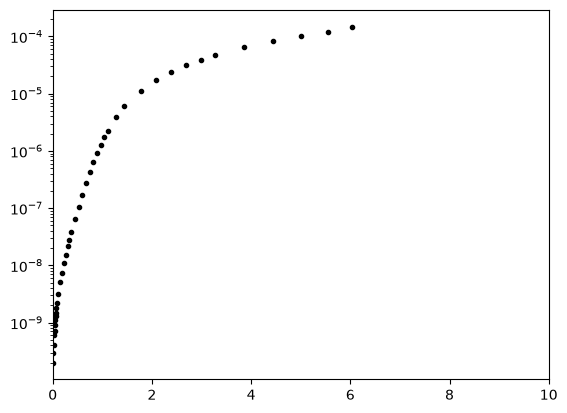

[0.         0.0075168  0.01503459 0.02255239 0.03006919 0.03758698
 0.04510378 0.05262058 0.06013738 0.06765417 0.07516997 0.09020356
 0.11275095 0.15032494 0.18789492 0.22545491 0.26300489 0.30053288
 0.33806686 0.37556285 0.45048182 0.52525279 0.59977676 0.67395873
 0.7475597  0.82077367 0.89314764 0.96470861 1.03543158 1.10530955
 1.27678947 1.4427994  1.77019925 2.0813391  2.39357895 2.6887188
 2.99075865 3.2764985  3.8532782  4.43735789 4.99736759 5.55191729
 6.03209699]


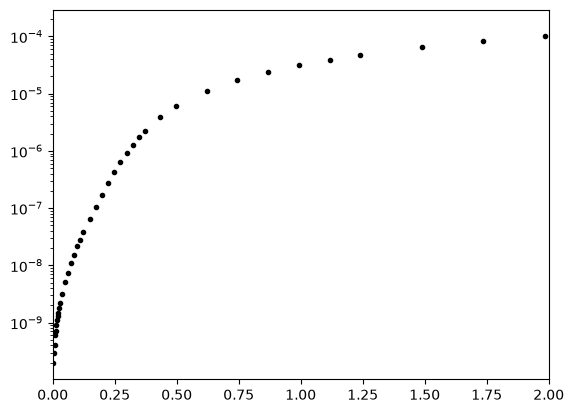

In [21]:
#Plotten:
plt.semilogy(UD,ID,'k.',label = 'Spankracht over tegen Stroom door de diode')
plt.xlim(0,10)
plt.show()

plt.semilogy(UD2,ID,'k.')

plt.xlim(0,2)
print(UD)

In [ ]:
#Curvefit
q = -1.602*10**-9
n = 2
t = 293
i0 = None
k_B = None
def funcfit(I0,q,VD,n,kB,T):
    return I0 * (np.exp((-q*VD)/(n*kB*T)) - 1)

val, cov = curve_fit(funcfit,UD,ID,p0 =(i0,k_B,t))
xtest = np.linspace(0.8*UD,1.2*UD,10000)
ytest = funcfit(xtest,*val)
plt.semilogy(xtest,ytest,'r--',label = "Least Square Fit")

TypeError: Improper input: func input vector length N=3 must not exceed func output vector length M=1

In [ ]:
#Boltzmann constante berekenening (via optimale parameters)
I0, T, kB = val

In [ ]:
#Berekening van kB via b grootheid
b = None
Kb = -q/(n*b*T)

I0err, k_B err,Terr = np.sqrt(np.diag(cov))
ub = None #onzekerheid b
un = 0.1 #onzekerheid n
uKb = Kb*np.sqrt((ub/b)**2 + (un/n)**2 + (Terr/T)**2)

SyntaxError: cannot assign to function call (59163357.py, line 4)